In [1]:
from pathlib import Path
import pandas as pd

data_path = Path(r"D:\Air Quality Data in India\city_day.csv")
df = pd.read_csv(data_path)

print("حجم الداتا:", df.shape)
display(df.head())

حجم الداتا: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [2]:
display(df.dtypes.rename("نوع البيانات").to_frame())

missing_summary = pd.DataFrame({
    "عدد القيم الناقصة": df.isna().sum(),
    "نسبة النقص %": (df.isna().mean() * 100).round(2)
}).sort_values("نسبة النقص %", ascending=False)

display(missing_summary[missing_summary["عدد القيم الناقصة"] > 0])


print("عدد الصفوف المكررة:", df.duplicated().sum())
print("عدد المدن:", df["City"].nunique())

dates = pd.to_datetime(df["Date"], errors="coerce")
print("الفترة الزمنية:", dates.min().date(), "إلى", dates.max().date())

,نوع البيانات
City,str
Date,str
PM2.5,float64
PM10,float64
NO,float64
NO2,float64
NOx,float64
NH3,float64
CO,float64
SO2,float64


,عدد القيم الناقصة,نسبة النقص %
Xylene,18109,61.32
PM10,11140,37.72
NH3,10328,34.97
Toluene,8041,27.23
Benzene,5623,19.04
AQI,4681,15.85
AQI_Bucket,4681,15.85
PM2.5,4598,15.57
NOx,4185,14.17
O3,4022,13.62


عدد الصفوف المكررة: 0
عدد المدن: 26
الفترة الزمنية: 2015-01-01 إلى 2020-07-01


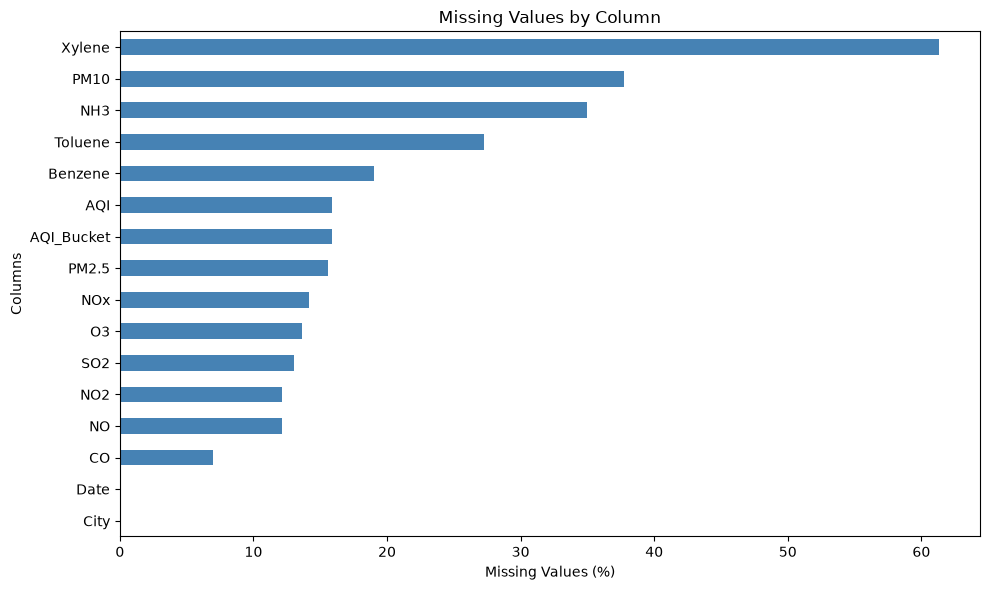

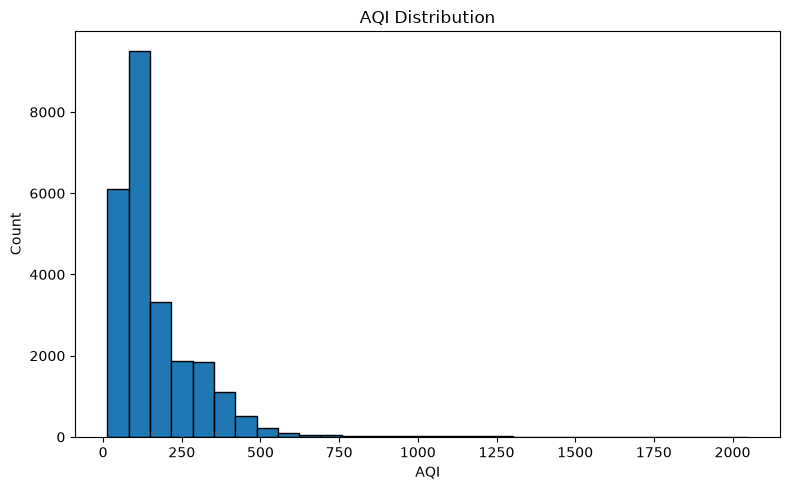

,Count
AQI_Bucket,
Moderate,8829
Satisfactory,8224
NaN,4681
Poor,2781
Very Poor,2337
Good,1341
Severe,1338


In [3]:
import matplotlib.pyplot as plt

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

missing_pct = df.isna().mean().mul(100).sort_values()

plt.figure(figsize=(10, 6))
missing_pct.plot(kind="barh", color="steelblue")
plt.xlabel("Missing Values (%)")
plt.ylabel("Columns")
plt.title("Missing Values by Column")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
df["AQI"].dropna().plot(kind="hist", bins=30, edgecolor="black")
plt.xlabel("AQI")
plt.ylabel("Count")
plt.title("AQI Distribution")
plt.tight_layout()
plt.show()

display(
    df["AQI_Bucket"]
    .value_counts(dropna=False)
    .rename_axis("AQI_Bucket")
    .to_frame("Count")
)

,العدد,النسبة المئوية
AQI_Bucket,,
Good,1341,5.40
Satisfactory,8224,33.09
Moderate,8829,35.53
Poor,2781,11.19
Very Poor,2337,9.40
Severe,1338,5.38


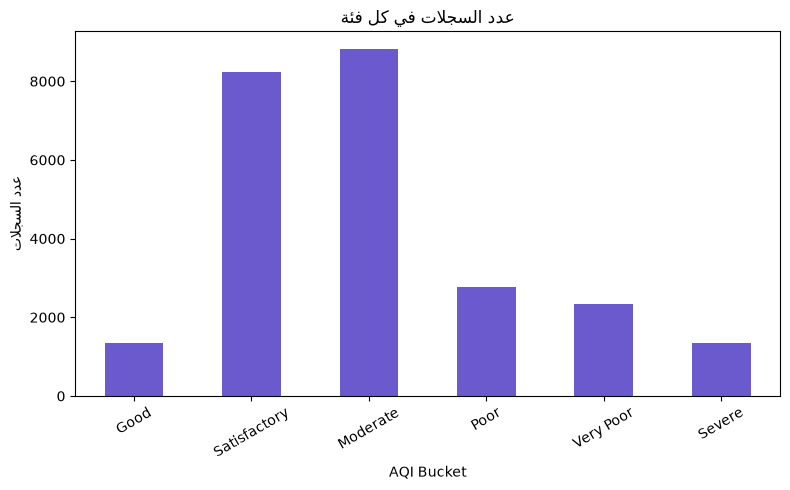

,City,Date,AQI,AQI_Bucket
1145,Ahmedabad,2018-02-19,2049.0,Severe
1136,Ahmedabad,2018-02-10,1917.0,Severe
560,Ahmedabad,2016-07-14,1842.0,Severe
1048,Ahmedabad,2017-11-14,1747.0,Severe
1463,Ahmedabad,2019-01-03,1719.0,Severe
1417,Ahmedabad,2018-11-18,1672.0,Severe
1420,Ahmedabad,2018-11-21,1646.0,Severe
1407,Ahmedabad,2018-11-08,1630.0,Severe
1127,Ahmedabad,2018-02-01,1613.0,Severe
1746,Ahmedabad,2019-10-13,1595.0,Severe


In [4]:
bucket_order = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

bucket_counts = df["AQI_Bucket"].value_counts().reindex(bucket_order, fill_value=0)

bucket_summary = pd.DataFrame({
    "العدد": bucket_counts,
    "النسبة المئوية": (bucket_counts / bucket_counts.sum() * 100).round(2)
})

display(bucket_summary)

bucket_counts.plot(kind="bar", figsize=(8, 5), color="slateblue")
plt.xlabel("AQI Bucket")
plt.ylabel("عدد السجلات")
plt.title("عدد السجلات في كل فئة")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(
    df.nlargest(10, "AQI")[["City", "Date", "AQI", "AQI_Bucket"]]
)

In [5]:
pollutant_columns = [
    "PM2.5",
    "PM10",
    "NO2",
    "NH3",
    "CO",
    "SO2",
    "O3"
]

high_aqi_rows = df.nlargest(10, "AQI")

print("عدد السجلات التي يتجاوز فيها AQI قيمة 500:",
      int((df["AQI"] > 500).sum()))

display(
    high_aqi_rows[
        ["City", "Date", "AQI", "AQI_Bucket"] + pollutant_columns
    ]
)

عدد السجلات التي يتجاوز فيها AQI قيمة 500: 543


,City,Date,AQI,AQI_Bucket,PM2.5,PM10,NO2,NH3,CO,SO2,O3
1145,Ahmedabad,2018-02-19,2049.0,Severe,242.66,NaN,199.17,NaN,132.47,NaN,44.06
1136,Ahmedabad,2018-02-10,1917.0,Severe,185.77,NaN,172.84,NaN,124.01,120.94,40.97
560,Ahmedabad,2016-07-14,1842.0,Severe,38.13,NaN,48.06,NaN,46.51,23.13,NaN
1048,Ahmedabad,2017-11-14,1747.0,Severe,207.19,NaN,146.18,NaN,118.02,160.06,37.21
1463,Ahmedabad,2019-01-03,1719.0,Severe,131.50,NaN,75.82,NaN,119.68,55.29,43.25
1417,Ahmedabad,2018-11-18,1672.0,Severe,127.46,NaN,77.65,NaN,108.81,63.63,48.32
1420,Ahmedabad,2018-11-21,1646.0,Severe,86.52,NaN,66.59,NaN,115.87,44.24,36.00
1407,Ahmedabad,2018-11-08,1630.0,Severe,205.21,NaN,100.87,NaN,93.31,75.95,61.17
1127,Ahmedabad,2018-02-01,1613.0,Severe,189.12,NaN,178.13,NaN,94.00,168.44,39.06
1746,Ahmedabad,2019-10-13,1595.0,Severe,194.36,335.86,207.05,NaN,119.30,NaN,27.16


In [6]:
above_500 = df.loc[df["AQI"] > 500]

display(
    above_500["AQI_Bucket"]
    .value_counts(dropna=False)
    .to_frame("عدد السجلات")
)

df["AQI_Capped"] = df["AQI"].clip(upper=500)

print("عدد السجلات فوق 500:", len(above_500))
print("أقصى AQI أصلي:", df["AQI"].max())
print("أقصى AQI في العمود الجديد:", df["AQI_Capped"].max())

,عدد السجلات
AQI_Bucket,
Severe,543


عدد السجلات فوق 500: 543
أقصى AQI أصلي: 2049.0
أقصى AQI في العمود الجديد: 500.0


In [7]:
df = df.sort_values(["City", "Date"]).reset_index(drop=True)

next_date = df.groupby("City")["Date"].shift(-1)
has_next_day = next_date == df["Date"] + pd.Timedelta(days=1)

print("السجلات التي لها قراءة في اليوم التالي:", int(has_next_day.sum()))
print("النسبة المئوية:", round(has_next_day.mean() * 100, 2), "%")

السجلات التي لها قراءة في اليوم التالي: 29505
النسبة المئوية: 99.91 %


In [8]:
next_date = df.groupby("City")["Date"].shift(-1)
has_next_day = next_date.eq(df["Date"] + pd.Timedelta(days=1))

df["AQI_Next_Day"] = (
    df.groupby("City")["AQI_Capped"]
    .shift(-1)
    .where(has_next_day)
)

df["AQI_Bucket_Next_Day"] = (
    df.groupby("City")["AQI_Bucket"]
    .shift(-1)
    .where(has_next_day)
)

print("أهداف AQI المتاحة:", df["AQI_Next_Day"].notna().sum())
print("أهداف التصنيف المتاحة:", df["AQI_Bucket_Next_Day"].notna().sum())

display(
    df[
        [
            "City",
            "Date",
            "AQI_Capped",
            "AQI_Next_Day",
            "AQI_Bucket",
            "AQI_Bucket_Next_Day"
        ]
    ].head(10)
)

أهداف AQI المتاحة: 24849
أهداف التصنيف المتاحة: 24849


,City,Date,AQI_Capped,AQI_Next_Day,AQI_Bucket,AQI_Bucket_Next_Day
0,Ahmedabad,2015-01-01,NaN,NaN,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,NaN,NaN
5,Ahmedabad,2015-01-06,NaN,NaN,NaN,NaN
6,Ahmedabad,2015-01-07,NaN,NaN,NaN,NaN
7,Ahmedabad,2015-01-08,NaN,NaN,NaN,NaN
8,Ahmedabad,2015-01-09,NaN,NaN,NaN,NaN
9,Ahmedabad,2015-01-10,NaN,NaN,NaN,NaN


In [9]:
df["Forecast_Date"] = df["Date"] + pd.Timedelta(days=1)
df["Forecast_Year"] = df["Forecast_Date"].dt.year
df["Forecast_Month"] = df["Forecast_Date"].dt.month
df["Forecast_DayOfWeek"] = df["Forecast_Date"].dt.dayofweek

display(
    df.loc[
        df["AQI_Next_Day"].notna(),
        [
            "City",
            "Date",
            "Forecast_Date",
            "Forecast_Year",
            "Forecast_Month",
            "Forecast_DayOfWeek",
            "AQI_Next_Day"
        ]
    ].head()
)

,City,Date,Forecast_Date,Forecast_Year,Forecast_Month,Forecast_DayOfWeek,AQI_Next_Day
27,Ahmedabad,2015-01-28,2015-01-29,2015,1,3,209.0
28,Ahmedabad,2015-01-29,2015-01-30,2015,1,4,328.0
29,Ahmedabad,2015-01-30,2015-01-31,2015,1,5,500.0
30,Ahmedabad,2015-01-31,2015-02-01,2015,2,6,500.0
31,Ahmedabad,2015-02-01,2015-02-02,2015,2,0,500.0


In [10]:
model_data = df.dropna(
    subset=["AQI_Next_Day", "AQI_Bucket_Next_Day"]
).copy()

unique_dates = model_data["Forecast_Date"].sort_values().unique()
split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_index]

train_data = model_data[
    model_data["Forecast_Date"] < split_date
].copy()

test_data = model_data[
    model_data["Forecast_Date"] >= split_date
].copy()

print("تاريخ بداية الاختبار:", split_date)
print("عدد سجلات التدريب:", len(train_data))
print("عدد سجلات الاختبار:", len(test_data))
print(
    "فترة التدريب:",
    train_data["Forecast_Date"].min().date(),
    "إلى",
    train_data["Forecast_Date"].max().date()
)
print(
    "فترة الاختبار:",
    test_data["Forecast_Date"].min().date(),
    "إلى",
    test_data["Forecast_Date"].max().date()
)

تاريخ بداية الاختبار: 2019-05-27 00:00:00
عدد سجلات التدريب: 16017
عدد سجلات الاختبار: 8832
فترة التدريب: 2015-01-02 إلى 2019-05-26
فترة الاختبار: 2019-05-27 إلى 2020-07-01


In [11]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

numeric_features = [
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene",
    "AQI_Capped",
    "Forecast_Year",
    "Forecast_Month",
    "Forecast_DayOfWeek"
]

categorical_features = [
    "City",
    "AQI_Bucket"
]

feature_columns = numeric_features + categorical_features

X_train = train_data[feature_columns]
y_train = train_data["AQI_Next_Day"]

X_test = test_data[feature_columns]
y_test = test_data["AQI_Next_Day"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

regression_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

regression_pipeline.fit(X_train, y_train)

linear_predictions = regression_pipeline.predict(X_test)
mean_predictions = np.full(len(y_test), y_train.mean())

results = pd.DataFrame({
    "Model": ["Mean Baseline", "Linear Regression"],
    "MAE": [
        mean_absolute_error(y_test, mean_predictions),
        mean_absolute_error(y_test, linear_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, mean_predictions)),
        np.sqrt(mean_squared_error(y_test, linear_predictions))
    ],
    "R2": [
        r2_score(y_test, mean_predictions),
        r2_score(y_test, linear_predictions)
    ]
})

display(results.round(3))

,Model,MAE,RMSE,R2
0,Mean Baseline,95.591,108.005,-0.401
1,Linear Regression,20.640,32.342,0.874


أقل توقع: 21.08
أعلى توقع: 645.54
توقعات خارج نطاق 0 إلى 500: 22


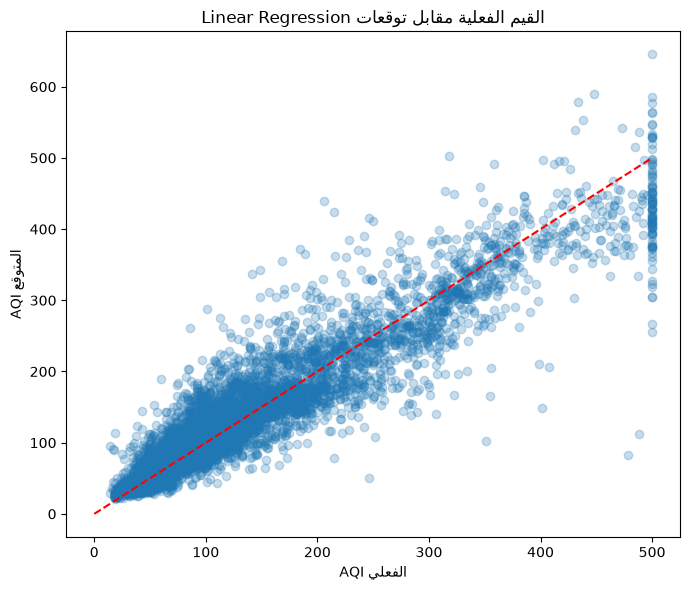

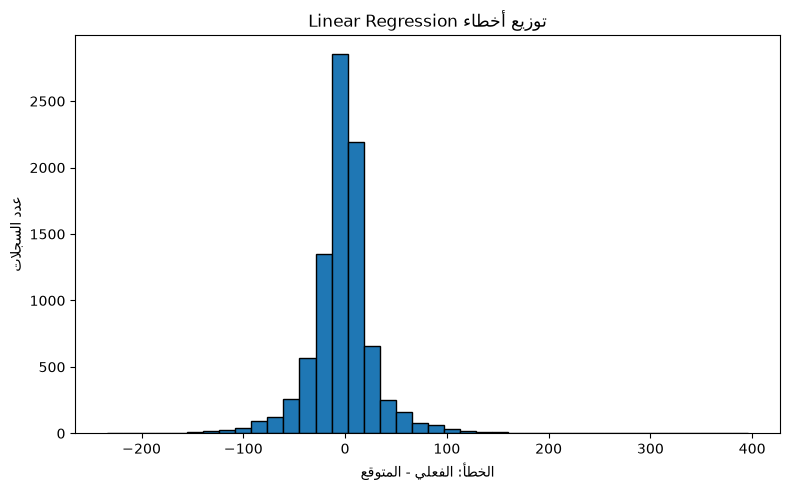

In [12]:
residuals = y_test - linear_predictions

print("أقل توقع:", round(linear_predictions.min(), 2))
print("أعلى توقع:", round(linear_predictions.max(), 2))
print(
    "توقعات خارج نطاق 0 إلى 500:",
    int(((linear_predictions < 0) | (linear_predictions > 500)).sum())
)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, linear_predictions, alpha=0.25)
plt.plot([0, 500], [0, 500], color="red", linestyle="--")
plt.xlabel("AQI الفعلي")
plt.ylabel("AQI المتوقع")
plt.title("القيم الفعلية مقابل توقعات Linear Regression")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=40, edgecolor="black")
plt.xlabel("الخطأ: الفعلي - المتوقع")
plt.ylabel("عدد السجلات")
plt.title("توزيع أخطاء Linear Regression")
plt.tight_layout()
plt.show()

In [13]:
linear_predictions_capped = np.clip(linear_predictions, 0, 500)

prediction_comparison = pd.DataFrame({
    "نوع التوقع": ["الأصلي", "محدود بين 0 و500"],
    "MAE": [
        mean_absolute_error(y_test, linear_predictions),
        mean_absolute_error(y_test, linear_predictions_capped)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, linear_predictions)),
        np.sqrt(mean_squared_error(y_test, linear_predictions_capped))
    ],
    "R2": [
        r2_score(y_test, linear_predictions),
        r2_score(y_test, linear_predictions_capped)
    ]
})

display(prediction_comparison.round(3))

,نوع التوقع,MAE,RMSE,R2
0,الأصلي,20.640,32.342,0.874
1,محدود بين 0 و500,20.519,32.149,0.876


In [14]:
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso

numeric_pipeline_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

scaled_preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline_scaled, numeric_features),
    ("categorical", categorical_pipeline_scaled, categorical_features)
])

regularized_candidates = {
    "Ridge": Ridge(alpha=10.0),
    "Lasso": Lasso(alpha=0.1, max_iter=20000)
}

regularized_models = {}

model_scores = [{
    "Model": "Linear Regression",
    "MAE": mean_absolute_error(y_test, linear_predictions_capped),
    "RMSE": np.sqrt(mean_squared_error(y_test, linear_predictions_capped)),
    "R2": r2_score(y_test, linear_predictions_capped)
}]

for name, estimator in regularized_candidates.items():
    model_pipeline = Pipeline([
        ("preprocessor", clone(scaled_preprocessor)),
        ("model", estimator)
    ])

    model_pipeline.fit(X_train, y_train)

    predictions = np.clip(model_pipeline.predict(X_test), 0, 500)
    regularized_models[name] = model_pipeline

    model_scores.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

display(pd.DataFrame(model_scores).round(3))

,Model,MAE,RMSE,R2
0,Linear Regression,20.519,32.149,0.876
1,Ridge,20.449,32.085,0.876
2,Lasso,19.948,31.796,0.879


In [15]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.base import clone

lasso_predictions = np.clip(
    regularized_models["Lasso"].predict(X_test),
    0,
    500
)

decision_tree_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=10,
        random_state=42
    ))
])

decision_tree_pipeline.fit(X_train, y_train)

decision_tree_predictions = np.clip(
    decision_tree_pipeline.predict(X_test),
    0,
    500
)

decision_tree_results = pd.DataFrame({
    "Model": ["Lasso", "Decision Tree"],
    "MAE": [
        mean_absolute_error(y_test, lasso_predictions),
        mean_absolute_error(y_test, decision_tree_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, lasso_predictions)),
        np.sqrt(mean_squared_error(y_test, decision_tree_predictions))
    ],
    "R2": [
        r2_score(y_test, lasso_predictions),
        r2_score(y_test, decision_tree_predictions)
    ]
})

display(decision_tree_results.round(3))

,Model,MAE,RMSE,R2
0,Lasso,19.948,31.796,0.879
1,Decision Tree,19.907,32.132,0.876


In [16]:
from sklearn.ensemble import RandomForestRegressor

random_forest_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=150,
        max_depth=16,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    ))
])

random_forest_pipeline.fit(X_train, y_train)

random_forest_predictions = np.clip(
    random_forest_pipeline.predict(X_test),
    0,
    500
)

predictions_to_compare = {
    "Linear Regression": linear_predictions_capped,
    "Ridge": np.clip(regularized_models["Ridge"].predict(X_test), 0, 500),
    "Lasso": lasso_predictions,
    "Decision Tree": decision_tree_predictions,
    "Random Forest": random_forest_predictions
}

forest_comparison = pd.DataFrame([
    {
        "Model": name,
        "MAE": mean_absolute_error(y_test, prediction),
        "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
        "R2": r2_score(y_test, prediction)
    }
    for name, prediction in predictions_to_compare.items()
])

display(forest_comparison.round(3).sort_values("RMSE"))

,Model,MAE,RMSE,R2
4,Random Forest,17.180,27.739,0.908
2,Lasso,19.948,31.796,0.879
1,Ridge,20.449,32.085,0.876
3,Decision Tree,19.907,32.132,0.876
0,Linear Regression,20.519,32.149,0.876


In [17]:
from sklearn.ensemble import ExtraTreesRegressor

extra_trees_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", ExtraTreesRegressor(
        n_estimators=150,
        max_depth=16,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    ))
])

extra_trees_pipeline.fit(X_train, y_train)

extra_trees_predictions = np.clip(
    extra_trees_pipeline.predict(X_test),
    0,
    500
)

tree_comparison = pd.DataFrame([
    {
        "Model": "Random Forest",
        "MAE": mean_absolute_error(y_test, random_forest_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, random_forest_predictions)),
        "R2": r2_score(y_test, random_forest_predictions)
    },
    {
        "Model": "Extra Trees",
        "MAE": mean_absolute_error(y_test, extra_trees_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, extra_trees_predictions)),
        "R2": r2_score(y_test, extra_trees_predictions)
    }
])

display(tree_comparison.round(3).sort_values("RMSE"))

,Model,MAE,RMSE,R2
0,Random Forest,17.180,27.739,0.908
1,Extra Trees,18.025,29.115,0.898


In [18]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        loss="squared_error",
        random_state=42
    ))
])

gradient_boosting_pipeline.fit(X_train, y_train)

gradient_boosting_predictions = np.clip(
    gradient_boosting_pipeline.predict(X_test),
    0,
    500
)

boosting_comparison = pd.DataFrame([
    {
        "Model": "Random Forest",
        "MAE": mean_absolute_error(y_test, random_forest_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, random_forest_predictions)),
        "R2": r2_score(y_test, random_forest_predictions)
    },
    {
        "Model": "Extra Trees",
        "MAE": mean_absolute_error(y_test, extra_trees_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, extra_trees_predictions)),
        "R2": r2_score(y_test, extra_trees_predictions)
    },
    {
        "Model": "Gradient Boosting",
        "MAE": mean_absolute_error(y_test, gradient_boosting_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, gradient_boosting_predictions)),
        "R2": r2_score(y_test, gradient_boosting_predictions)
    }
])

display(boosting_comparison.round(3).sort_values("RMSE"))

,Model,MAE,RMSE,R2
0,Random Forest,17.180,27.739,0.908
1,Extra Trees,18.025,29.115,0.898
2,Gradient Boosting,19.216,30.908,0.885


In [19]:
from sklearn.base import clone
from sklearn.ensemble import AdaBoostRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

ada_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", AdaBoostRegressor(
        n_estimators=100,
        learning_rate=0.05,
        random_state=42
    ))
])

ada_model.fit(X_train, y_train)

ada_predictions = ada_model.predict(X_test)
ada_predictions = np.clip(ada_predictions, 0, 500)

ada_results = pd.DataFrame([{
    "Model": "AdaBoost",
    "MAE": mean_absolute_error(y_test, ada_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, ada_predictions)),
    "R2": r2_score(y_test, ada_predictions)
}])

ada_results.round(3)

,Model,MAE,RMSE,R2
0,AdaBoost,31.167,41.079,0.797


In [20]:
from sklearn.base import clone
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

bagging_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", BaggingRegressor(
        estimator=DecisionTreeRegressor(max_depth=12, min_samples_leaf=10),
        n_estimators=100,
        max_samples=0.8,
        random_state=42,
        n_jobs=-1
    ))
])

bagging_model.fit(X_train, y_train)

bagging_predictions = bagging_model.predict(X_test)
bagging_predictions = np.clip(bagging_predictions, 0, 500)

bagging_results = pd.DataFrame([{
    "Model": "Bagging",
    "MAE": mean_absolute_error(y_test, bagging_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, bagging_predictions)),
    "R2": r2_score(y_test, bagging_predictions)
}])

bagging_results.round(3)

,Model,MAE,RMSE,R2
0,Bagging,17.098,27.982,0.906


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

numeric_columns = X_train.select_dtypes(include=np.number).columns
categorical_columns = X_train.select_dtypes(exclude=np.number).columns

knn_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_columns),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_columns)
])

knn_model = Pipeline([
    ("preprocessor", knn_preprocessor),
    ("model", KNeighborsRegressor(n_neighbors=5, weights="distance"))
])

knn_model.fit(X_train, y_train)

knn_predictions = knn_model.predict(X_test)
knn_predictions = np.clip(knn_predictions, 0, 500)

knn_results = pd.DataFrame([{
    "Model": "KNN",
    "MAE": mean_absolute_error(y_test, knn_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, knn_predictions)),
    "R2": r2_score(y_test, knn_predictions)
}])

knn_results.round(3)

,Model,MAE,RMSE,R2
0,KNN,25.419,38.325,0.824


In [22]:
from sklearn.base import clone
from sklearn.svm import LinearSVR
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

svr_model = Pipeline([
    ("preprocessor", clone(knn_preprocessor)),
    ("model", LinearSVR(
        C=1.0,
        epsilon=0.1,
        max_iter=20000,
        dual="auto",
        random_state=42
    ))
])

svr_model.fit(X_train, y_train)

svr_predictions = svr_model.predict(X_test)
svr_predictions = np.clip(svr_predictions, 0, 500)

svr_results = pd.DataFrame([{
    "Model": "Linear SVR",
    "MAE": mean_absolute_error(y_test, svr_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, svr_predictions)),
    "R2": r2_score(y_test, svr_predictions)
}])

svr_results.round(3)

,Model,MAE,RMSE,R2
0,Linear SVR,19.388,31.727,0.879


In [23]:
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

mlp_pipeline = Pipeline([
    ("preprocessor", clone(knn_preprocessor)),
    ("model", MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=300,
        random_state=42
    ))
])

mlp_model = TransformedTargetRegressor(
    regressor=mlp_pipeline,
    transformer=StandardScaler()
)

mlp_model.fit(X_train, y_train)

mlp_predictions = mlp_model.predict(X_test)
mlp_predictions = np.clip(mlp_predictions, 0, 500)

mlp_results = pd.DataFrame([{
    "Model": "MLP Regressor",
    "MAE": mean_absolute_error(y_test, mlp_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, mlp_predictions)),
    "R2": r2_score(y_test, mlp_predictions)
}])

mlp_results.round(3)

,Model,MAE,RMSE,R2
0,MLP Regressor,30.775,42.998,0.778


In [24]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

features_cv = X_train.reset_index(drop=True)
target_cv = pd.Series(y_train).reset_index(drop=True)
dates_cv = pd.to_datetime(train_data["Forecast_Date"]).reset_index(drop=True)
unique_dates_cv = dates_cv.drop_duplicates().sort_values().to_numpy()

model_factories = {
    "Random Forest": lambda: RandomForestRegressor(
        n_estimators=150,
        max_depth=16,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    ),
    "Extra Trees": lambda: ExtraTreesRegressor(
        n_estimators=150,
        max_depth=16,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    ),
    "Bagging": lambda: BaggingRegressor(
        estimator=DecisionTreeRegressor(max_depth=12, min_samples_leaf=10),
        n_estimators=100,
        max_samples=0.8,
        random_state=42,
        n_jobs=-1
    )
}

cv_records = []
time_splitter = TimeSeriesSplit(n_splits=3)

for fold, (train_date_idx, val_date_idx) in enumerate(time_splitter.split(unique_dates_cv), start=1):
    train_mask = dates_cv.isin(unique_dates_cv[train_date_idx]).to_numpy()
    val_mask = dates_cv.isin(unique_dates_cv[val_date_idx]).to_numpy()

    X_fold_train = features_cv.iloc[train_mask]
    X_fold_val = features_cv.iloc[val_mask]
    y_fold_train = target_cv.iloc[train_mask]
    y_fold_val = target_cv.iloc[val_mask]

    for model_name, model_factory in model_factories.items():
        fold_model = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("model", model_factory())
        ])

        fold_model.fit(X_fold_train, y_fold_train)
        fold_predictions = np.clip(fold_model.predict(X_fold_val), 0, 500)

        cv_records.append({
            "Fold": fold,
            "Model": model_name,
            "MAE": mean_absolute_error(y_fold_val, fold_predictions),
            "RMSE": np.sqrt(mean_squared_error(y_fold_val, fold_predictions)),
            "R2": r2_score(y_fold_val, fold_predictions)
        })

cv_details = pd.DataFrame(cv_records)
cv_summary = cv_details.groupby("Model")[["MAE", "RMSE", "R2"]].mean()
cv_summary.sort_values("MAE").round(3)

,MAE,RMSE,R2
Model,,,
Bagging,28.892,42.863,0.866
Extra Trees,28.902,42.651,0.867
Random Forest,29.212,43.019,0.865


In [25]:
from sklearn.model_selection import TimeSeriesSplit
import pandas as pd

fold_periods = []

for fold, (train_date_idx, val_date_idx) in enumerate(
    TimeSeriesSplit(n_splits=3).split(unique_dates_cv),
    start=1
):
    validation_dates = pd.to_datetime(unique_dates_cv[val_date_idx])

    fold_periods.append({
        "Fold": fold,
        "Validation Start": validation_dates.min().date(),
        "Validation End": validation_dates.max().date()
    })

fold_periods = pd.DataFrame(fold_periods)

cv_details.merge(fold_periods, on="Fold").sort_values(
    ["Fold", "MAE"]
).round(3)

,Fold,Model,MAE,RMSE,R2,Validation Start,Validation End
2,1,Bagging,35.400,48.728,0.827,2016-02-09,2017-03-15
1,1,Extra Trees,35.574,48.489,0.829,2016-02-09,2017-03-15
0,1,Random Forest,35.610,48.430,0.829,2016-02-09,2017-03-15
4,2,Extra Trees,26.925,40.850,0.884,2017-03-16,2018-04-20
5,2,Bagging,26.931,40.657,0.885,2017-03-16,2018-04-20
3,2,Random Forest,27.177,40.698,0.885,2017-03-16,2018-04-20
7,3,Extra Trees,24.207,38.616,0.888,2018-04-21,2019-05-26
8,3,Bagging,24.343,39.203,0.885,2018-04-21,2019-05-26
6,3,Random Forest,24.849,39.929,0.881,2018-04-21,2019-05-26


In [26]:
from sklearn.model_selection import TimeSeriesSplit
import pandas as pd

fold_stats = []

for fold, (train_date_idx, val_date_idx) in enumerate(
    TimeSeriesSplit(n_splits=3).split(unique_dates_cv),
    start=1
):
    train_mask = dates_cv.isin(unique_dates_cv[train_date_idx]).to_numpy()
    val_mask = dates_cv.isin(unique_dates_cv[val_date_idx]).to_numpy()

    y_fold_train = target_cv.iloc[train_mask]
    y_fold_val = target_cv.iloc[val_mask]
    validation_dates = pd.to_datetime(unique_dates_cv[val_date_idx])

    fold_stats.append({
        "Fold": fold,
        "Training Records": len(y_fold_train),
        "Validation Records": len(y_fold_val),
        "Validation Start": validation_dates.min().date(),
        "Validation End": validation_dates.max().date(),
        "Training Mean AQI": y_fold_train.mean(),
        "Validation Mean AQI": y_fold_val.mean(),
        "Validation Median AQI": y_fold_val.median(),
        "Validation P90 AQI": y_fold_val.quantile(0.9),
        "Validation Max AQI": y_fold_val.max()
    })

pd.DataFrame(fold_stats).round(2)

,Fold,Training Records,Validation Records,Validation Start,Validation End,Training Mean AQI,Validation Mean AQI,Validation Median AQI,Validation P90 AQI,Validation Max AQI
0,1,2063,2912,2016-02-09,2017-03-15,214.92,192.38,150.0,371.0,500.0
1,2,4975,4244,2017-03-16,2018-04-20,201.73,180.11,134.0,360.0,500.0
2,3,9219,6798,2018-04-21,2019-05-26,191.77,167.44,122.0,349.0,500.0


In [27]:
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd

cv_splits = []

for train_date_idx, val_date_idx in TimeSeriesSplit(n_splits=3).split(unique_dates_cv):
    train_mask = dates_cv.isin(unique_dates_cv[train_date_idx]).to_numpy()
    val_mask = dates_cv.isin(unique_dates_cv[val_date_idx]).to_numpy()

    cv_splits.append((
        np.flatnonzero(train_mask),
        np.flatnonzero(val_mask)
    ))

extra_trees_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", ExtraTreesRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

parameter_options = {
    "model__n_estimators": [100, 150],
    "model__max_depth": [12, 16, None],
    "model__min_samples_leaf": [3, 5],
    "model__max_features": [0.8, 1.0]
}

extra_trees_search = RandomizedSearchCV(
    estimator=extra_trees_pipeline,
    param_distributions=parameter_options,
    n_iter=8,
    scoring="neg_mean_absolute_error",
    cv=cv_splits,
    random_state=42,
    n_jobs=1,
    refit=True
)

extra_trees_search.fit(features_cv, target_cv)

extra_tuning_results = pd.DataFrame(extra_trees_search.cv_results_)
extra_tuning_results["Mean CV MAE"] = -extra_tuning_results["mean_test_score"]
extra_tuning_results["Std CV MAE"] = extra_tuning_results["std_test_score"]

extra_tuning_results[
    ["rank_test_score", "Mean CV MAE", "Std CV MAE", "params"]
].sort_values("rank_test_score").head(5).round(3)

,rank_test_score,Mean CV MAE,Std CV MAE,params
6,1,28.904,4.759,"{'model__n_estimators': 150, 'model__min_sampl..."
5,2,29.019,4.877,"{'model__n_estimators': 150, 'model__min_sampl..."
1,3,29.044,4.942,"{'model__n_estimators': 100, 'model__min_sampl..."
0,4,29.048,4.877,"{'model__n_estimators': 100, 'model__min_sampl..."
3,5,29.092,5.067,"{'model__n_estimators': 100, 'model__min_sampl..."


In [28]:
from sklearn.base import clone
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
import pandas as pd

bagging_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", BaggingRegressor(
        estimator=DecisionTreeRegressor(random_state=42),
        random_state=42,
        n_jobs=-1
    ))
])

bagging_parameter_options = {
    "model__n_estimators": [50, 100, 150],
    "model__max_samples": [0.7, 0.85, 1.0],
    "model__max_features": [0.8, 1.0],
    "model__estimator__max_depth": [8, 12, None],
    "model__estimator__min_samples_leaf": [5, 10, 15]
}

bagging_search = RandomizedSearchCV(
    estimator=bagging_pipeline,
    param_distributions=bagging_parameter_options,
    n_iter=8,
    scoring="neg_mean_absolute_error",
    cv=cv_splits,
    random_state=42,
    n_jobs=1,
    refit=True
)

bagging_search.fit(features_cv, target_cv)

bagging_tuning_results = pd.DataFrame(bagging_search.cv_results_)
bagging_tuning_results["Mean CV MAE"] = -bagging_tuning_results["mean_test_score"]
bagging_tuning_results["Std CV MAE"] = bagging_tuning_results["std_test_score"]

bagging_tuning_results[
    ["rank_test_score", "Mean CV MAE", "Std CV MAE", "params"]
].sort_values("rank_test_score").head(5).round(3)

,rank_test_score,Mean CV MAE,Std CV MAE,params
7,1,28.989,4.473,"{'model__n_estimators': 50, 'model__max_sample..."
0,2,28.989,4.709,"{'model__n_estimators': 150, 'model__max_sampl..."
5,3,29.016,4.664,"{'model__n_estimators': 150, 'model__max_sampl..."
6,4,29.056,4.754,"{'model__n_estimators': 150, 'model__max_sampl..."
4,5,29.343,4.636,"{'model__n_estimators': 100, 'model__max_sampl..."


In [29]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

final_model = extra_trees_search.best_estimator_

final_predictions = final_model.predict(X_test)
final_predictions = np.clip(final_predictions, 0, 500)

final_results = pd.DataFrame([{
    "Model": "Tuned Extra Trees",
    "MAE": mean_absolute_error(y_test, final_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, final_predictions)),
    "R2": r2_score(y_test, final_predictions)
}])

final_results.round(3)

,Model,MAE,RMSE,R2
0,Tuned Extra Trees,18.103,28.982,0.899


,Feature,Importance
11,numeric__AQI_Capped,0.504588
38,categorical__AQI_Bucket_Severe,0.139703
0,numeric__PM2.5,0.092013
39,categorical__AQI_Bucket_Very Poor,0.075465
36,categorical__AQI_Bucket_Poor,0.051771
35,categorical__AQI_Bucket_Moderate,0.043465
15,categorical__City_Ahmedabad,0.017879
1,numeric__PM10,0.011688
6,numeric__CO,0.009260
2,numeric__NO,0.005772


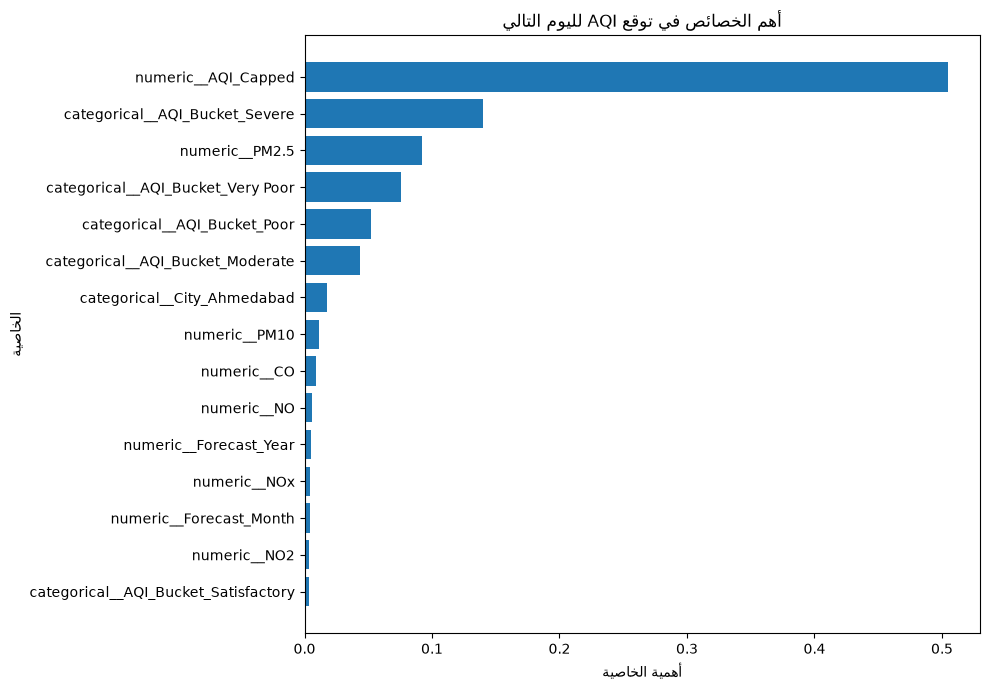

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()
feature_values = final_model.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_values
}).sort_values("Importance", ascending=False)

top_features = importance_df.head(15).sort_values("Importance")

display(importance_df.head(15))

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("أهمية الخاصية")
plt.ylabel("الخاصية")
plt.title("أهم الخصائص في توقع AQI لليوم التالي")
plt.tight_layout()
plt.show()

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

def make_preprocessor(data):
    numeric_columns = data.select_dtypes(include=np.number).columns.tolist()
    categorical_columns = data.select_dtypes(exclude=np.number).columns.tolist()

    return ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), numeric_columns),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_columns)
    ])

feature_scenarios = {
    "All Features": features_cv,
    "Without AQI_Capped": features_cv.drop(columns=["AQI_Capped"]),
    "Without AQI and Bucket": features_cv.drop(columns=["AQI_Capped", "AQI_Bucket"])
}

best_extra_trees_params = {
    key.replace("model__", ""): value
    for key, value in extra_trees_search.best_params_.items()
}

ablation_records = []

for scenario_name, scenario_features in feature_scenarios.items():
    for fold, (train_indices, val_indices) in enumerate(cv_splits, start=1):
        fold_model = Pipeline([
            ("preprocessor", make_preprocessor(scenario_features)),
            ("model", ExtraTreesRegressor(
                **best_extra_trees_params,
                random_state=42,
                n_jobs=-1
            ))
        ])

        fold_model.fit(
            scenario_features.iloc[train_indices],
            target_cv.iloc[train_indices]
        )

        predictions = np.clip(
            fold_model.predict(scenario_features.iloc[val_indices]),
            0,
            500
        )
        actual = target_cv.iloc[val_indices]

        ablation_records.append({
            "Scenario": scenario_name,
            "Fold": fold,
            "MAE": mean_absolute_error(actual, predictions),
            "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
            "R2": r2_score(actual, predictions)
        })

ablation_details = pd.DataFrame(ablation_records)

ablation_summary = ablation_details.groupby("Scenario")[[
    "MAE", "RMSE", "R2"
]].mean()

ablation_summary.round(3)

,MAE,RMSE,R2
Scenario,,,
All Features,28.904,42.641,0.867
Without AQI and Bucket,31.309,45.165,0.851
Without AQI_Capped,29.416,42.940,0.865


In [32]:
train_class_data = train_data.dropna(subset=["AQI_Bucket_Next_Day"]).copy()
test_class_data = test_data.dropna(subset=["AQI_Bucket_Next_Day"]).copy()

feature_columns = X_train.columns.tolist()

X_train_class = train_class_data[feature_columns]
y_train_class = train_class_data["AQI_Bucket_Next_Day"]

X_test_class = test_class_data[feature_columns]
y_test_class = test_class_data["AQI_Bucket_Next_Day"]

train_class_counts = y_train_class.value_counts()
test_class_counts = y_test_class.value_counts()

class_distribution = pd.DataFrame({
    "Training Count": train_class_counts,
    "Test Count": test_class_counts
}).fillna(0).astype(int)

class_distribution["Training %"] = (
    class_distribution["Training Count"] / len(y_train_class) * 100
).round(2)

class_distribution["Test %"] = (
    class_distribution["Test Count"] / len(y_test_class) * 100
).round(2)

class_distribution.sort_values("Training Count", ascending=False)

,Training Count,Test Count,Training %,Test %
AQI_Bucket_Next_Day,,,,
Moderate,6054,2775,37.80,31.42
Satisfactory,4340,3884,27.10,43.98
Poor,2137,644,13.34,7.29
Very Poor,1958,379,12.22,4.29
Severe,1110,227,6.93,2.57
Good,418,923,2.61,10.45


In [33]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
import pandas as pd

classification_models = {
    "Most Frequent Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        ))
    ])
}

classification_records = []

for model_name, model in classification_models.items():
    model.fit(X_train_class, y_train_class)
    predictions = model.predict(X_test_class)

    classification_records.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_class, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test_class, predictions),
        "Macro F1": f1_score(y_test_class, predictions, average="macro", zero_division=0)
    })

classification_results = pd.DataFrame(classification_records)
classification_results.round(3)

c:\Users\Hackshahaat\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Model,Accuracy,Balanced Accuracy,Macro F1
0,Most Frequent Baseline,0.314,0.167,0.080
1,Logistic Regression,0.691,0.725,0.677


In [34]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
import pandas as pd

logistic_scaled_model = Pipeline([
    ("preprocessor", clone(knn_preprocessor)),
    ("model", LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_scaled_model.fit(X_train_class, y_train_class)
logistic_scaled_predictions = logistic_scaled_model.predict(X_test_class)

scaled_logistic_result = pd.DataFrame([{
    "Model": "Logistic Regression Scaled",
    "Accuracy": accuracy_score(y_test_class, logistic_scaled_predictions),
    "Balanced Accuracy": balanced_accuracy_score(y_test_class, logistic_scaled_predictions),
    "Macro F1": f1_score(
        y_test_class,
        logistic_scaled_predictions,
        average="macro",
        zero_division=0
    ),
    "Iterations": int(logistic_scaled_model.named_steps["model"].n_iter_.max())
}])

scaled_logistic_result.round(3)

,Model,Accuracy,Balanced Accuracy,Macro F1,Iterations
0,Logistic Regression Scaled,0.716,0.722,0.691,161


In [35]:
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
import pandas as pd

tree_classifiers = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=16,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=150,
        max_depth=16,
        min_samples_leaf=5,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    )
}

tree_classification_records = []

for model_name, classifier in tree_classifiers.items():
    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", classifier)
    ])

    model.fit(X_train_class, y_train_class)
    predictions = model.predict(X_test_class)

    tree_classification_records.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_class, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test_class, predictions),
        "Macro F1": f1_score(
            y_test_class,
            predictions,
            average="macro",
            zero_division=0
        )
    })

tree_classification_results = pd.DataFrame(tree_classification_records)
tree_classification_results.sort_values("Macro F1", ascending=False).round(3)

,Model,Accuracy,Balanced Accuracy,Macro F1
1,Random Forest,0.763,0.757,0.735
2,Extra Trees,0.743,0.725,0.703
0,Decision Tree,0.678,0.719,0.665


,precision,recall,f1-score,support
Good,0.702,0.739,0.720,923.000
Moderate,0.792,0.704,0.745,2775.000
Poor,0.562,0.688,0.619,644.000
Satisfactory,0.808,0.823,0.816,3884.000
Severe,0.750,0.885,0.812,227.000
Very Poor,0.696,0.702,0.699,379.000
accuracy,0.763,0.763,0.763,0.763
macro avg,0.718,0.757,0.735,8832.000
weighted avg,0.768,0.763,0.764,8832.000


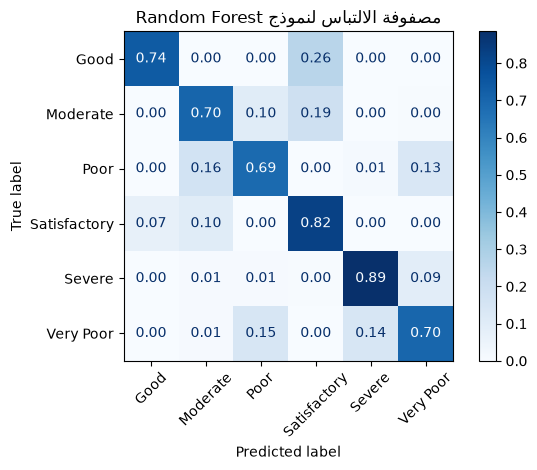

In [36]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

random_forest_class_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=150,
        max_depth=16,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    ))
])

random_forest_class_model.fit(X_train_class, y_train_class)
random_forest_class_predictions = random_forest_class_model.predict(X_test_class)

class_labels = sorted(y_train_class.unique())

class_report = classification_report(
    y_test_class,
    random_forest_class_predictions,
    labels=class_labels,
    output_dict=True,
    zero_division=0
)

display(pd.DataFrame(class_report).T.round(3))

ConfusionMatrixDisplay.from_predictions(
    y_test_class,
    random_forest_class_predictions,
    labels=class_labels,
    display_labels=class_labels,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    xticks_rotation=45
)

plt.title("مصفوفة الالتباس لنموذج Random Forest")
plt.tight_layout()
plt.show()

In [37]:
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
import pandas as pd

additional_classifiers = {
    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        n_jobs=-1
    ),
    "Linear SVM": LinearSVC(
        C=1.0,
        class_weight="balanced",
        max_iter=10000,
        dual="auto",
        random_state=42
    )
}

additional_classification_records = []

for model_name, classifier in additional_classifiers.items():
    model = Pipeline([
        ("preprocessor", clone(knn_preprocessor)),
        ("model", classifier)
    ])

    model.fit(X_train_class, y_train_class)
    predictions = model.predict(X_test_class)

    additional_classification_records.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_class, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test_class, predictions),
        "Macro F1": f1_score(
            y_test_class,
            predictions,
            average="macro",
            zero_division=0
        )
    })

additional_classification_results = pd.DataFrame(additional_classification_records)
additional_classification_results.sort_values("Macro F1", ascending=False).round(3)

,Model,Accuracy,Balanced Accuracy,Macro F1
1,Linear SVM,0.742,0.693,0.695
0,KNN,0.683,0.614,0.624


In [38]:
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
import pandas as pd

balanced_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_class
)

boosting_classifiers = {
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ),
    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=2,
            random_state=42
        ),
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    )
}

boosting_classification_records = []

for model_name, classifier in boosting_classifiers.items():
    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", classifier)
    ])

    model.fit(
        X_train_class,
        y_train_class,
        model__sample_weight=balanced_sample_weights
    )

    predictions = model.predict(X_test_class)

    boosting_classification_records.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_class, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test_class, predictions),
        "Macro F1": f1_score(
            y_test_class,
            predictions,
            average="macro",
            zero_division=0
        )
    })

boosting_classification_results = pd.DataFrame(boosting_classification_records)
boosting_classification_results.sort_values("Macro F1", ascending=False).round(3)

,Model,Accuracy,Balanced Accuracy,Macro F1
0,Gradient Boosting,0.713,0.760,0.704
1,AdaBoost,0.666,0.726,0.663


In [40]:
baseline_result = classification_results[
    classification_results["Model"] == "Most Frequent Baseline"
]

classification_comparison = pd.concat([
    baseline_result,
    scaled_logistic_result.drop(columns=["Iterations"]),
    tree_classification_results,
    additional_classification_results,
    boosting_classification_results
], ignore_index=True)

classification_comparison.sort_values(
    ["Macro F1", "Balanced Accuracy"],
    ascending=False
).round(3)

,Model,Accuracy,Balanced Accuracy,Macro F1
3,Random Forest,0.763,0.757,0.735
7,Gradient Boosting,0.713,0.760,0.704
4,Extra Trees,0.743,0.725,0.703
6,Linear SVM,0.742,0.693,0.695
1,Logistic Regression Scaled,0.716,0.722,0.691
2,Decision Tree,0.678,0.719,0.665
8,AdaBoost,0.666,0.726,0.663
5,KNN,0.683,0.614,0.624
0,Most Frequent Baseline,0.314,0.167,0.080


In [41]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
import pandas as pd

class_features_cv = X_train_class.reset_index(drop=True)
class_target_cv = pd.Series(y_train_class).reset_index(drop=True)
class_dates_cv = pd.to_datetime(
    train_class_data["Forecast_Date"]
).reset_index(drop=True)

unique_class_dates = class_dates_cv.drop_duplicates().sort_values().to_numpy()
classification_cv_records = []

for fold, (train_date_idx, val_date_idx) in enumerate(
    TimeSeriesSplit(n_splits=3).split(unique_class_dates),
    start=1
):
    train_mask = class_dates_cv.isin(
        unique_class_dates[train_date_idx]
    ).to_numpy()
    val_mask = class_dates_cv.isin(
        unique_class_dates[val_date_idx]
    ).to_numpy()

    X_fold_train = class_features_cv.iloc[train_mask]
    X_fold_val = class_features_cv.iloc[val_mask]
    y_fold_train = class_target_cv.iloc[train_mask]
    y_fold_val = class_target_cv.iloc[val_mask]

    fold_classifiers = {
        "Random Forest": RandomForestClassifier(
            n_estimators=150,
            max_depth=16,
            min_samples_leaf=5,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=42
        ),
        "Extra Trees": ExtraTreesClassifier(
            n_estimators=150,
            max_depth=16,
            min_samples_leaf=5,
            class_weight="balanced",
            n_jobs=-1,
            random_state=42
        ),
        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=2,
            random_state=42
        )
    }

    for model_name, classifier in fold_classifiers.items():
        fold_model = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("model", classifier)
        ])

        if model_name == "Gradient Boosting":
            fold_weights = compute_sample_weight(
                class_weight="balanced",
                y=y_fold_train
            )
            fold_model.fit(
                X_fold_train,
                y_fold_train,
                model__sample_weight=fold_weights
            )
        else:
            fold_model.fit(X_fold_train, y_fold_train)

        predictions = fold_model.predict(X_fold_val)

        classification_cv_records.append({
            "Fold": fold,
            "Model": model_name,
            "Accuracy": accuracy_score(y_fold_val, predictions),
            "Balanced Accuracy": balanced_accuracy_score(
                y_fold_val,
                predictions
            ),
            "Macro F1": f1_score(
                y_fold_val,
                predictions,
                average="macro",
                zero_division=0
            )
        })

classification_cv_details = pd.DataFrame(classification_cv_records)

classification_cv_summary = classification_cv_details.groupby("Model")[
    ["Accuracy", "Balanced Accuracy", "Macro F1"]
].mean()

classification_cv_summary.sort_values(
    "Macro F1",
    ascending=False
).round(3)

,Accuracy,Balanced Accuracy,Macro F1
Model,,,
Extra Trees,0.686,0.661,0.645
Random Forest,0.705,0.649,0.641
Gradient Boosting,0.674,0.662,0.626


In [42]:
from sklearn.model_selection import TimeSeriesSplit
import pandas as pd

classification_fold_periods = []

for fold, (_, val_date_idx) in enumerate(
    TimeSeriesSplit(n_splits=3).split(unique_class_dates),
    start=1
):
    validation_dates = pd.to_datetime(unique_class_dates[val_date_idx])

    classification_fold_periods.append({
        "Fold": fold,
        "Validation Start": validation_dates.min().date(),
        "Validation End": validation_dates.max().date()
    })

classification_fold_periods = pd.DataFrame(classification_fold_periods)

classification_cv_details.merge(
    classification_fold_periods,
    on="Fold"
).sort_values(
    ["Fold", "Macro F1"],
    ascending=[True, False]
).round(3)

,Fold,Model,Accuracy,Balanced Accuracy,Macro F1,Validation Start,Validation End
1,1,Extra Trees,0.648,0.614,0.612,2016-02-09,2017-03-15
0,1,Random Forest,0.652,0.553,0.557,2016-02-09,2017-03-15
2,1,Gradient Boosting,0.616,0.558,0.551,2016-02-09,2017-03-15
3,2,Random Forest,0.724,0.690,0.669,2017-03-16,2018-04-20
4,2,Extra Trees,0.689,0.679,0.646,2017-03-16,2018-04-20
5,2,Gradient Boosting,0.683,0.714,0.644,2017-03-16,2018-04-20
6,3,Random Forest,0.737,0.703,0.698,2018-04-21,2019-05-26
8,3,Gradient Boosting,0.723,0.715,0.682,2018-04-21,2019-05-26
7,3,Extra Trees,0.722,0.689,0.678,2018-04-21,2019-05-26


,Number of Clusters,Inertia,Silhouette Score
0,2,118.768,0.379
1,3,74.201,0.356
2,4,58.430,0.230
3,5,43.431,0.254
4,6,36.280,0.260
5,7,27.932,0.275


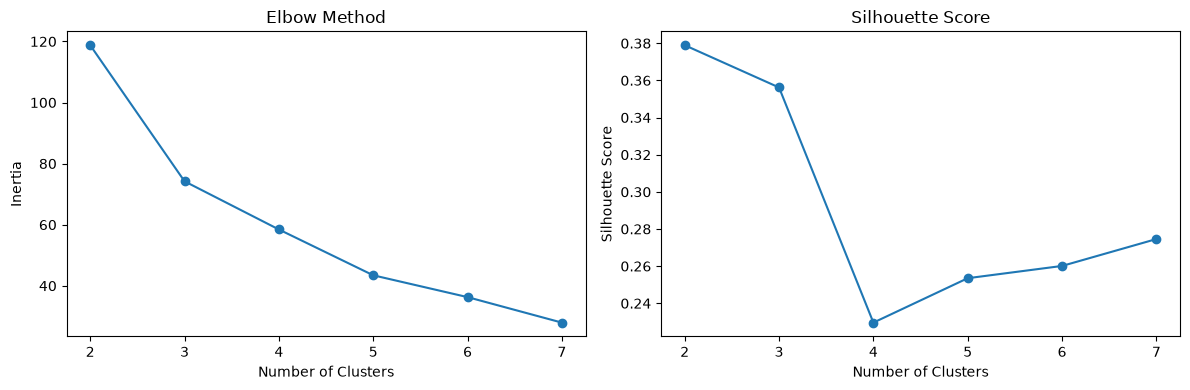

In [43]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cluster_features = [
    "PM2.5",
    "PM10",
    "NO2",
    "CO",
    "SO2",
    "O3",
    "AQI_Capped"
]

city_profiles = df.groupby("City")[cluster_features].median()
city_profiles = city_profiles.replace([np.inf, -np.inf], np.nan)
city_profiles = city_profiles.dropna(axis=1, how="all")

city_imputer = SimpleImputer(strategy="median")
city_scaler = StandardScaler()

city_features_imputed = city_imputer.fit_transform(city_profiles)
city_features_scaled = city_scaler.fit_transform(city_features_imputed)

cluster_scores = []

for k in range(2, 8):
    kmeans = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=42
    )

    cluster_labels = kmeans.fit_predict(city_features_scaled)

    cluster_scores.append({
        "Number of Clusters": k,
        "Inertia": kmeans.inertia_,
        "Silhouette Score": silhouette_score(
            city_features_scaled,
            cluster_labels
        )
    })

cluster_scores = pd.DataFrame(cluster_scores)
display(cluster_scores.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    cluster_scores["Number of Clusters"],
    cluster_scores["Inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    cluster_scores["Number of Clusters"],
    cluster_scores["Silhouette Score"],
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [44]:
final_kmeans = KMeans(
    n_clusters=2,
    n_init=20,
    random_state=42
)

city_cluster_results = city_profiles.copy()
city_cluster_results["Cluster"] = final_kmeans.fit_predict(city_features_scaled)

active_cluster_features = city_profiles.columns.tolist()

cluster_profiles = city_cluster_results.groupby("Cluster")[
    active_cluster_features
].mean().round(2)

cities_by_cluster = (
    city_cluster_results
    .reset_index()
    .groupby("Cluster")["City"]
    .agg(", ".join)
    .to_frame("Cities")
)

display(cities_by_cluster)
display(cluster_profiles)

,Cities
Cluster,
0,"Aizawl, Amaravati, Amritsar, Bengaluru, Brajra..."
1,"Ahmedabad, Bhopal, Delhi, Gurugram, Jaipur, Lu..."


,PM2.5,PM10,NO2,CO,SO2,O3,AQI_Capped
Cluster,,,,,,,
0,35.12,74.01,15.31,0.80,10.72,22.71,91.08
1,73.56,142.68,33.11,3.23,15.89,39.91,214.93


,Number of Clusters,KMeans Silhouette,Agglomerative Silhouette
0,2,0.379,0.421
1,3,0.356,0.375
2,4,0.230,0.221
3,5,0.254,0.268
4,6,0.260,0.270
5,7,0.275,0.297


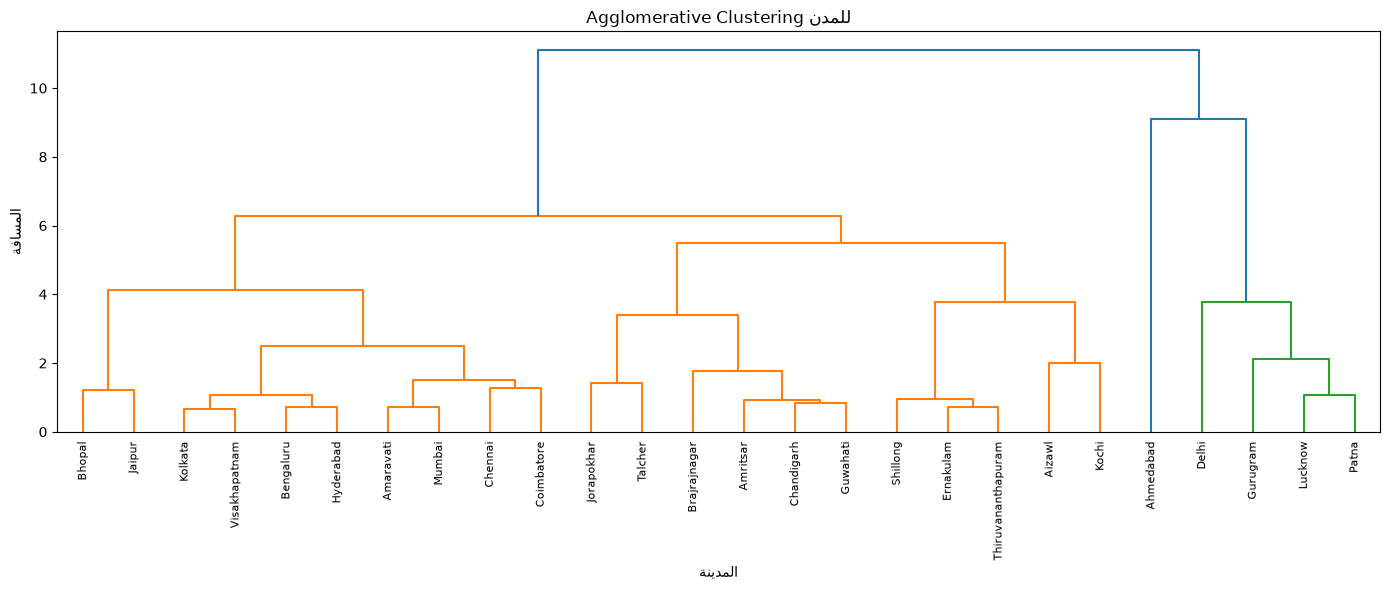

In [45]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
import pandas as pd
import matplotlib.pyplot as plt

agglomerative_scores = []

for k in range(2, 8):
    agglomerative = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = agglomerative.fit_predict(city_features_scaled)

    agglomerative_scores.append({
        "Number of Clusters": k,
        "Agglomerative Silhouette": silhouette_score(
            city_features_scaled,
            labels
        )
    })

agglomerative_scores = pd.DataFrame(agglomerative_scores)

cluster_method_comparison = cluster_scores[
    ["Number of Clusters", "Silhouette Score"]
].rename(columns={
    "Silhouette Score": "KMeans Silhouette"
}).merge(
    agglomerative_scores,
    on="Number of Clusters"
)

display(cluster_method_comparison.round(3))

hierarchy_matrix = linkage(city_features_scaled, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(
    hierarchy_matrix,
    labels=city_profiles.index.astype(str),
    leaf_rotation=90,
    leaf_font_size=8
)
plt.title("Agglomerative Clustering للمدن")
plt.xlabel("المدينة")
plt.ylabel("المسافة")
plt.tight_layout()
plt.show()

In [46]:
from sklearn.cluster import AgglomerativeClustering
import pandas as pd

final_agglomerative = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

agglomerative_labels = final_agglomerative.fit_predict(
    city_features_scaled
)

city_agglomerative_results = city_profiles.copy()
city_agglomerative_results["Cluster"] = agglomerative_labels

agglomerative_city_lists = (
    city_agglomerative_results
    .reset_index()
    .groupby("Cluster")["City"]
    .agg(", ".join)
    .to_frame("Cities")
)

agglomerative_profiles = city_agglomerative_results.groupby("Cluster")[
    active_cluster_features
].mean().round(2)

display(agglomerative_city_lists)
display(agglomerative_profiles)

,Cities
Cluster,
0,"Ahmedabad, Delhi, Gurugram, Lucknow, Patna"
1,"Aizawl, Amaravati, Amritsar, Bengaluru, Bhopal..."


,PM2.5,PM10,NO2,CO,SO2,O3,AQI_Capped
Cluster,,,,,,,
0,84.07,154.70,33.91,4.20,17.67,34.71,252.50
1,36.28,78.26,16.82,0.81,10.79,25.73,93.93


In [47]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

dbscan_records = []

for eps in [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0]:
    for min_samples in [2, 3, 4]:
        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = dbscan.fit_predict(city_features_scaled)
        non_noise_mask = labels != -1
        cluster_labels = set(labels[non_noise_mask])
        number_of_clusters = len(cluster_labels)

        if number_of_clusters >= 2 and non_noise_mask.sum() > number_of_clusters:
            score = silhouette_score(
                city_features_scaled[non_noise_mask],
                labels[non_noise_mask]
            )
        else:
            score = np.nan

        dbscan_records.append({
            "Epsilon": eps,
            "Min Samples": min_samples,
            "Number of Clusters": number_of_clusters,
            "Noise Cities": int((labels == -1).sum()),
            "Silhouette Score": score
        })

dbscan_results = pd.DataFrame(dbscan_records)

dbscan_results.sort_values(
    ["Min Samples", "Epsilon"]
).round(3)

,Epsilon,Min Samples,Number of Clusters,Noise Cities,Silhouette Score
0,1.0,2,4,14,0.456
3,1.5,2,3,5,0.341
6,2.0,2,2,2,0.331
9,2.5,2,1,2,NaN
12,3.0,2,1,1,NaN
15,3.5,2,1,1,NaN
18,4.0,2,1,1,NaN
1,1.0,3,3,16,0.551
4,1.5,3,1,9,NaN
7,2.0,3,2,2,0.331


In [48]:
from sklearn.cluster import DBSCAN
import pandas as pd

dbscan_model = DBSCAN(
    eps=2.0,
    min_samples=3
)

dbscan_labels = dbscan_model.fit_predict(city_features_scaled)

city_dbscan_results = city_profiles.copy()
city_dbscan_results["Cluster"] = dbscan_labels

assigned_cities = (
    city_dbscan_results[city_dbscan_results["Cluster"] != -1]
    .reset_index()
    .groupby("Cluster")["City"]
    .agg(", ".join)
    .to_frame("Cities")
)

dbscan_profiles = city_dbscan_results[
    city_dbscan_results["Cluster"] != -1
].groupby("Cluster")[active_cluster_features].mean().round(2)

noise_cities = city_dbscan_results[
    city_dbscan_results["Cluster"] == -1
].index.tolist()

display(assigned_cities)
display(dbscan_profiles)
print("Cities marked as noise:", ", ".join(noise_cities))
print("Number of noise cities:", len(noise_cities))

,Cities
Cluster,
0,"Aizawl, Amaravati, Amritsar, Bengaluru, Bhopal..."
1,"Gurugram, Lucknow, Patna"


,PM2.5,PM10,NO2,CO,SO2,O3,AQI_Capped
Cluster,,,,,,,
0,36.28,78.26,16.82,0.81,10.79,25.73,93.93
1,89.12,147.06,25.08,1.17,9.04,29.87,207.00


Cities marked as noise: Ahmedabad, Delhi
Number of noise cities: 2
